
🪙 RUNNING: ETHUSDT | 1h | 01/01/2025 -> 12/05/2026
⏳ Downloading ETHUSDT 1h...
✅ Data ready...
🚀 Running strategy...

🎯 STRATEGY - SMMA(10) + RSI(10) + KC(20,2.3) + STOP(Highest/Lowest Close 25) + ATR50 buffer + ADAPTIVE VOL FILTER
     Final Equity: 14429.6926
     Total Return: 0.4430
    CAGR (approx): 0.3114
     Max Drawdown: -0.0598
           Sharpe: 2.4636
           Trades: 131
          Winrate: 0.5115
    Avg PnL/Trade: 33.8144
    Profit Factor: 1.6819

💡 Estimated R:R: 1:1.61


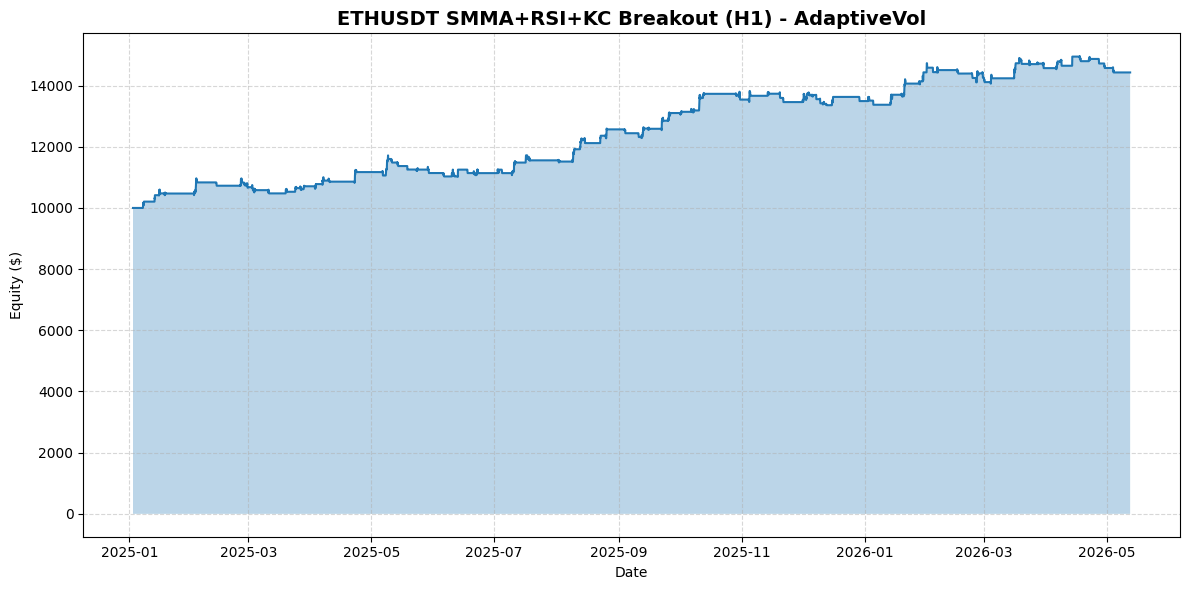


📊 Sample Trades:
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2025-01-08 04:00:00  SHORT  3462.650000  3343.118208  206.798165  Take Profit  10206.798165
1 2025-01-13 14:00:00  SHORT  3118.610000  2993.477312  210.159865  Take Profit  10416.958030
2 2025-01-16 05:00:00   LONG  3329.490000  3368.390000   58.873783    Time Exit  10475.831814
3 2025-01-18 22:00:00  SHORT  3277.085687  3280.460000   -4.281875    Time Exit  10471.549939
4 2025-02-02 13:00:00  SHORT  3117.237151  3087.470000   44.096022    Time Exit  10515.645961
5 2025-02-02 22:00:00  SHORT  2971.608389  2814.641187  222.080952  Take Profit  10737.726914
6 2025-02-03 01:00:00  SHORT  2838.605304  2634.957021  206.754958  Take Profit  10944.481872
7 2025-02-03 14:00:00  SHORT  2486.660000  2643.571734 -109.444819    Stop Loss  10835.037053
8 2025-02-13 07:00:00   LONG  2756.944955  2677.762989 -108.350371    Stop Loss  10726.686683
9 2025-02-25 07:00:00  SHORT  2513.520000 

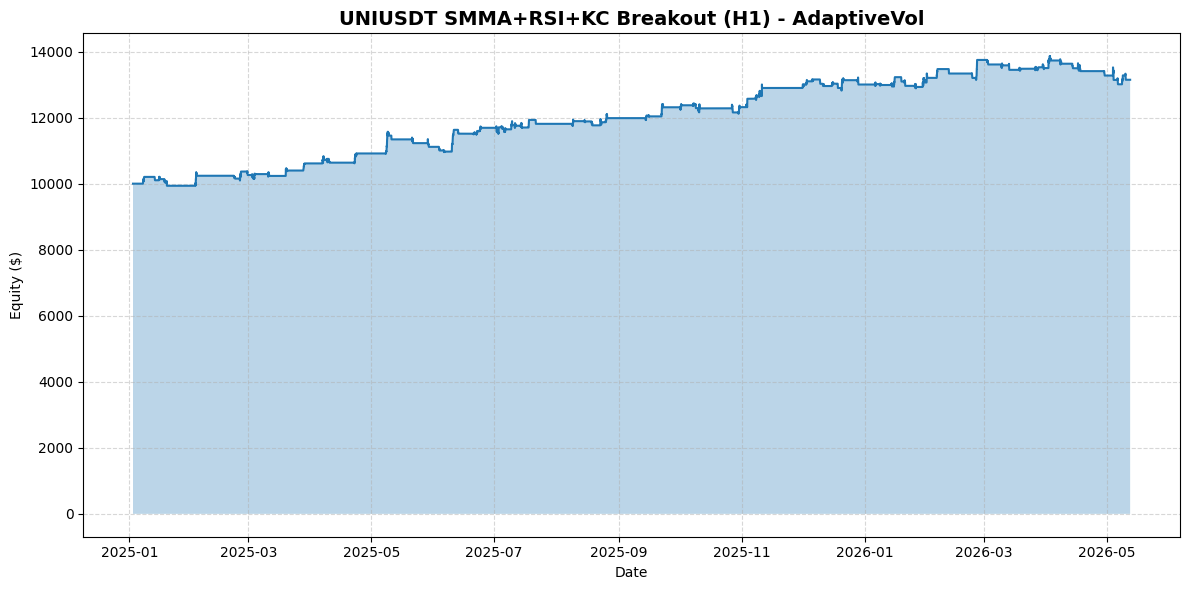


📊 Sample Trades:
            Exit Time   Type      Entry       Exit         PnL       Reason       Balance
0 2025-01-08 06:00:00  SHORT  14.116000  13.205462  204.769388  Take Profit  10204.769388
1 2025-01-13 15:00:00  SHORT  12.283000  12.686120 -102.047694    Stop Loss  10102.721694
2 2025-01-16 05:00:00   LONG  14.138000  14.284000   34.953445    Time Exit  10137.675139
3 2025-01-18 13:00:00  SHORT  13.923360  14.412745 -101.376751    Stop Loss  10036.298388
4 2025-01-19 14:00:00  SHORT  13.416545  13.906176 -100.362984    Stop Loss   9935.935404
5 2025-02-02 22:00:00  SHORT   9.650000   8.796784  210.114020  Take Profit  10146.049424
6 2025-02-03 01:00:00  SHORT   8.814640   7.715427  196.535822  Take Profit  10342.585246
7 2025-02-03 06:00:00  SHORT   7.713000   8.485763 -103.425852    Stop Loss  10239.159394
8 2025-02-22 10:00:00  SHORT   8.639000   8.933000  -85.566089    Time Exit  10153.593304
9 2025-02-25 07:00:00  SHORT   8.182422   7.648316  212.313402  Take Profit  10365

In [4]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch error:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # --- True Range ---
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # --- Wilder ATR (EMA alpha=1/n) ---
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_30"] = calc_atr(data["TR"], 30)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # --- SMMA(10) on CLOSE (RMA) ---
    data["SMMA_10_Close"] = data["Close"].ewm(alpha=1/10, min_periods=10, adjust=False).mean()

    # --- RSI(10) on CLOSE (rolling mean style) ---
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_10_Close"] = calc_rsi(data["Close"], 10)

    # --- Keltner Channel(20, dev=2.3) ---
    ema_20 = data["Close"].ewm(span=20, adjust=False).mean()
    atr_20_kc = calc_atr(data["TR"], 20)
    data["KC_Upper_20_2p3"] = ema_20 + 2.3 * atr_20_kc
    data["KC_Lower_20_2p3"] = ema_20 - 2.3 * atr_20_kc

    # --- Highest/Lowest Close window=25 ---
    data["Highest_Close_25"] = data["Close"].rolling(window=25).max()
    data["Lowest_Close_25"] = data["Close"].rolling(window=25).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (Adaptive Volatility Expansion Filter)
# =========================================================
class SMMA_RSI_KC_Breakout_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None  # "LONG" / "SHORT" / None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0

        self.pending_order = None

        # Params
        self.price_entry_mult = 2.4
        self.exit_after_bars = 14
        self.pending_expiration = 4

        self.sl_coef = 2.1
        self.tp_coef = 4.5

        # MM
        self.risk_pct = 0.01

        # ===== Adaptive Volatility Expansion Filter =====
        # Base filter: giữ chặt khi trend yếu
        self.vol_ratio_min_base = 1.05

        # Khi trend mạnh -> nới filter (lấy lại trade tốt bị mất)
        self.vol_ratio_min_trend = 1.00

        # Đo "trend strength" bằng khoảng cách giá so với SMMA, chuẩn hoá bởi ATR20
        # trend_strength = abs(Close(t-1) - SMMA10(t-1)) / ATR20(t-1)
        self.trend_strength_threshold = 0.60  # gợi ý: 0.4 ~ 0.9

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            # -----------------------------
            # A) Manage open position
            # -----------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx

                # Time exit
                if held >= self.exit_after_bars:
                    self.close_position(bar["Close"], t, "Time Exit")
                    self.append_equity(t)
                    continue

                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

            # -----------------------------
            # B) Manage pending order
            # -----------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])
                            self.open_position("LONG", fill, i,
                                               self.pending_order["sl_dist"],
                                               self.pending_order["tp_dist"])
                            self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])
                            self.open_position("SHORT", fill, i,
                                               self.pending_order["sl_dist"],
                                               self.pending_order["tp_dist"])
                            self.pending_order = None

            # -----------------------------
            # C) Compute signals -> place pending
            # -----------------------------
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # shift=1
                close_1 = self.df.iloc[i-1]["Close"]
                smma10_1 = self.df.iloc[i-1]["SMMA_10_Close"]

                # RSI slope shift=2 vs shift=1
                rsi_2 = self.df.iloc[i-2]["RSI_10_Close"]
                rsi_1 = self.df.iloc[i-1]["RSI_10_Close"]

                # KC shift=1
                kc_up_1 = self.df.iloc[i-1]["KC_Upper_20_2p3"]
                kc_lo_1 = self.df.iloc[i-1]["KC_Lower_20_2p3"]

                # ===== Adaptive Volatility Filter =====
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr50_1 = self.df.iloc[i-1]["ATR_50"]

                vol_ratio = (atr20_1 / atr50_1) if (atr50_1 is not None and atr50_1 > 0) else 0.0

                # trend strength (chuẩn hoá theo ATR20 để scale-free)
                trend_strength = (abs(close_1 - smma10_1) / atr20_1) if (atr20_1 is not None and atr20_1 > 0) else 0.0

                # chọn ngưỡng vol theo trạng thái trend
                vol_min = self.vol_ratio_min_trend if trend_strength >= self.trend_strength_threshold else self.vol_ratio_min_base
                vol_ok = (vol_ratio >= vol_min)

                long_signal = vol_ok and (close_1 > smma10_1) and (rsi_2 < rsi_1) and (open_0 > kc_up_1)
                short_signal = vol_ok and (close_1 < smma10_1) and (rsi_2 > rsi_1) and (open_0 < kc_lo_1)

                if (not long_signal) and (not short_signal):
                    self.append_equity(t)
                    continue

                # Entry uses shift=3
                highest_close_3 = self.df.iloc[i-3]["Highest_Close_25"]
                lowest_close_3 = self.df.iloc[i-3]["Lowest_Close_25"]
                atr50_3 = self.df.iloc[i-3]["ATR_50"]

                # SL/TP distance uses shift=1 (atr20_1 already)
                atr30_1 = self.df.iloc[i-1]["ATR_30"]
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr30_1

                if long_signal:
                    entry = highest_close_3 + self.price_entry_mult * atr50_3
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry = lowest_close_3 - self.price_entry_mult * atr50_3
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # -----------------------------
            # D) Append equity
            # -----------------------------
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = self.df.loc[t, "Close"]

        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk Fixed % Balance sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0
        self.qty = float(qty)

    def close_position(self, price: float, t, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = dd.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["PnL"] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df["PnL"] > 0]["PnL"].sum()
    gross_loss = abs(trades_df[trades_df["PnL"] < 0]["PnL"].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - SMMA(10) + RSI(10) + KC(20,2.3) + STOP(Highest/Lowest Close 25) + ATR50 buffer + ADAPTIVE VOL FILTER")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"] if metrics["Winrate"] > 0 else 0.0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} SMMA+RSI+KC Breakout (H1) - AdaptiveVol", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN (PORTFOLIO LOOP)
# =========================================================
if __name__ == "__main__":
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "12/05/2026"

    # symbols = [
    #     "ETHUSDT", "NEARUSDT", "ARBUSDT", "UNIUSDT"
    # ]
    symbols = [
        "ETHUSDT", "UNIUSDT"
    ]
    initial_balance = 10000.0
    min_bars = 400
    summary_rows = []

    for symbol in symbols:
        print("\n" + "=" * 90)
        print(f"🪙 RUNNING: {symbol} | {interval} | {start_date} -> {end_date}")
        print("=" * 90)

        df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

        if df_raw is None or df_raw.empty or len(df_raw) <= min_bars:
            print(f"❌ Insufficient data for {symbol}. Bars={0 if df_raw is None else len(df_raw)}")
            summary_rows.append({
                "Symbol": symbol, "Status": "Insufficient data",
                "Final Equity": np.nan, "Total Return": np.nan, "CAGR": np.nan,
                "MaxDD": np.nan, "Sharpe": np.nan, "Trades": 0,
                "Winrate": np.nan, "ProfitFactor": np.nan,
            })
            continue

        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)

        if df_calc.empty or len(df_calc) <= min_bars:
            print(f"❌ Insufficient after indicators for {symbol}. Bars={len(df_calc)}")
            summary_rows.append({
                "Symbol": symbol, "Status": "Insufficient after indicators",
                "Final Equity": np.nan, "Total Return": np.nan, "CAGR": np.nan,
                "MaxDD": np.nan, "Sharpe": np.nan, "Trades": 0,
                "Winrate": np.nan, "ProfitFactor": np.nan,
            })
            continue

        print("🚀 Running strategy...")
        bt = SMMA_RSI_KC_Breakout_Backtester(df_calc, initial_balance=initial_balance)

        # Bạn có thể tune nhanh:
        # bt.vol_ratio_min_base = 1.06
        # bt.vol_ratio_min_trend = 1.00
        # bt.trend_strength_threshold = 0.55

        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())

            summary_rows.append({
                "Symbol": symbol, "Status": "OK",
                "Final Equity": float(metrics["Final Equity"]),
                "Total Return": float(metrics["Total Return"]),
                "CAGR": float(metrics["CAGR (approx)"]),
                "MaxDD": float(metrics["Max Drawdown"]),
                "Sharpe": float(metrics["Sharpe"]),
                "Trades": int(metrics["Trades"]),
                "Winrate": float(metrics["Winrate"]),
                "ProfitFactor": float(metrics["Profit Factor"]),
            })
        else:
            print("⚠️ No trades.")
            summary_rows.append({
                "Symbol": symbol, "Status": "No trades",
                "Final Equity": bt.equity_curve[-1]["equity"] if bt.equity_curve else initial_balance,
                "Total Return": np.nan, "CAGR": np.nan,
                "MaxDD": np.nan, "Sharpe": np.nan,
                "Trades": 0, "Winrate": np.nan, "ProfitFactor": np.nan,
            })

    summary_df = pd.DataFrame(summary_rows)
    if "Sharpe" in summary_df.columns:
        summary_df = summary_df.sort_values(by="Sharpe", ascending=False, na_position="last")
    else:
        summary_df = summary_df.sort_values(by="Final Equity", ascending=False, na_position="last")

    print("\n" + "#" * 90)
    print("📌 SUMMARY (sorted)")
    print("#" * 90)
    print(summary_df.to_string(index=False))



🪙 RUNNING: ETHUSDT | 1h | 01/01/2024 -> 13/02/2026
⏳ Downloading ETHUSDT 1h...
✅ Data ready...
🚀 Running strategy...

🎯 STRATEGY - SMMA(10) + RSI(10) + KC(20,2.3) + STOP(Highest/Lowest Close 25) + ATR50 buffer + ADAPTIVE VOL FILTER + FEES
     Final Equity: 23285.1269
     Total Return: 1.3285
    CAGR (approx): 0.4917
     Max Drawdown: -0.1357
           Sharpe: 1.8758
           Trades: 198
          Winrate: 0.5253
    Avg PnL/Trade: 67.0966
    Profit Factor: 1.5424

💡 Estimated R:R: 1:1.39


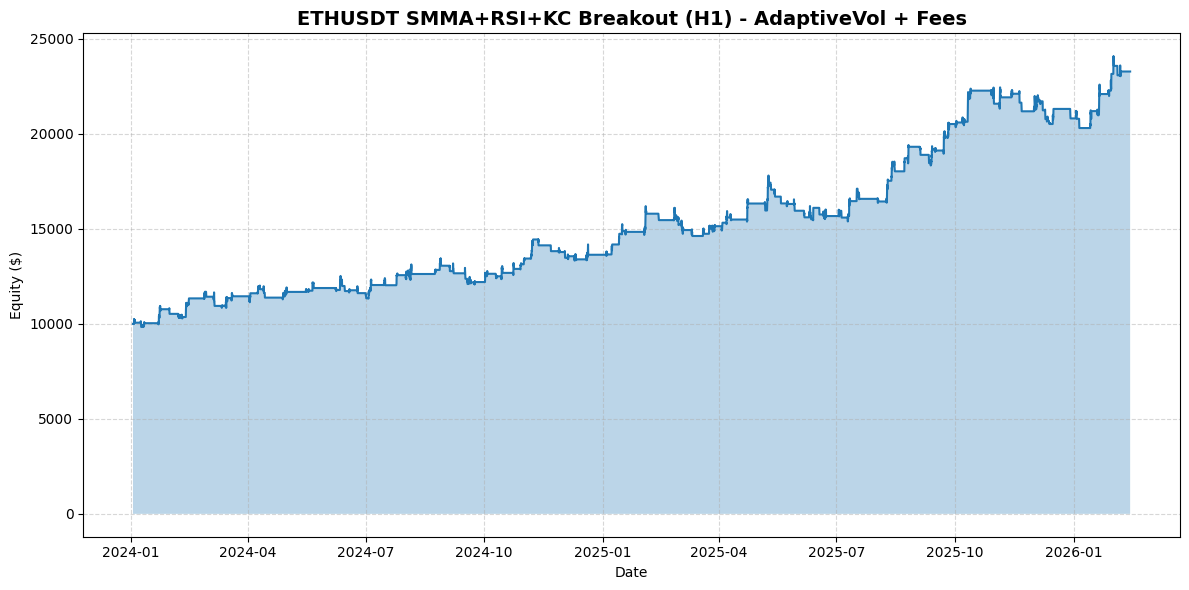


📊 Sample Trades:
            Exit Time   Type        Entry         Exit       Qty   PnL_gross   EntryFee    ExitFee   TotalFee     PnL_net       Reason       Balance
0 2024-01-04 03:00:00  SHORT  2248.550000  2231.080000  4.854179   84.802510  10.914865  10.830062  21.744927   63.057583    Time Exit  10063.057583
1 2024-01-09 00:00:00   LONG  2335.980000  2293.741945  4.764925 -201.261152  11.130769  10.929508  22.060276 -223.321428    Stop Loss   9839.736155
2 2024-01-11 13:00:00   LONG  2547.590000  2635.980000  2.362612  208.831239   6.018966   6.227797  12.246763  196.584476    Time Exit  10036.320631
3 2024-01-22 19:00:00  SHORT  2381.350000  2320.212913  6.763905  413.525454  16.107225  15.693700  31.800925  381.724528  Take Profit  10418.045160
4 2024-01-23 09:00:00  SHORT  2328.182940  2244.168741  4.681783  393.336244  10.900047  10.506711  21.406758  371.929486  Take Profit  10789.974646
5 2024-01-24 01:00:00  SHORT  2223.350000  2222.930000  4.419623    1.856242   9.826368 

In [ ]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch error:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # --- True Range ---
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # --- Wilder ATR (EMA alpha=1/n) ---
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_30"] = calc_atr(data["TR"], 30)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # --- SMMA(10) on CLOSE (RMA) ---
    data["SMMA_10_Close"] = data["Close"].ewm(alpha=1/10, min_periods=10, adjust=False).mean()

    # --- RSI(10) on CLOSE (rolling mean style) ---
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_10_Close"] = calc_rsi(data["Close"], 10)

    # --- Keltner Channel(20, dev=2.3) ---
    ema_20 = data["Close"].ewm(span=20, adjust=False).mean()
    atr_20_kc = calc_atr(data["TR"], 20)
    data["KC_Upper_20_2p3"] = ema_20 + 2.3 * atr_20_kc
    data["KC_Lower_20_2p3"] = ema_20 - 2.3 * atr_20_kc

    # --- Highest/Lowest Close window=25 ---
    data["Highest_Close_25"] = data["Close"].rolling(window=25).max()
    data["Lowest_Close_25"] = data["Close"].rolling(window=25).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (Adaptive Volatility Expansion Filter + FEES)
# =========================================================
class SMMA_RSI_KC_Breakout_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None  # "LONG" / "SHORT" / None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0

        self.pending_order = None

        # Params
        self.price_entry_mult = 2.4
        self.exit_after_bars = 14
        self.pending_expiration = 4

        self.sl_coef = 2.1
        self.tp_coef = 4.5

        # MM
        self.risk_pct = 0.02

        # ===== Fees (NEW) =====
        # Binance spot taker fee mặc định ~0.1% = 0.001 / side (vào + ra)
        self.fee_rate = 0.001
        self._last_entry_fee = 0.0

        # ===== Adaptive Volatility Expansion Filter =====
        self.vol_ratio_min_base = 1.05
        self.vol_ratio_min_trend = 1.00
        self.trend_strength_threshold = 0.60

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            # -----------------------------
            # A) Manage open position
            # -----------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx

                # Time exit
                if held >= self.exit_after_bars:
                    self.close_position(bar["Close"], t, "Time Exit")
                    self.append_equity(t)
                    continue

                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

            # -----------------------------
            # B) Manage pending order
            # -----------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])
                            self.open_position("LONG", fill, i,
                                               self.pending_order["sl_dist"],
                                               self.pending_order["tp_dist"])
                            self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])
                            self.open_position("SHORT", fill, i,
                                               self.pending_order["sl_dist"],
                                               self.pending_order["tp_dist"])
                            self.pending_order = None

            # -----------------------------
            # C) Compute signals -> place pending
            # -----------------------------
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # shift=1
                close_1 = self.df.iloc[i-1]["Close"]
                smma10_1 = self.df.iloc[i-1]["SMMA_10_Close"]

                # RSI slope shift=2 vs shift=1
                rsi_2 = self.df.iloc[i-2]["RSI_10_Close"]
                rsi_1 = self.df.iloc[i-1]["RSI_10_Close"]

                # KC shift=1
                kc_up_1 = self.df.iloc[i-1]["KC_Upper_20_2p3"]
                kc_lo_1 = self.df.iloc[i-1]["KC_Lower_20_2p3"]

                # ===== Adaptive Volatility Filter =====
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr50_1 = self.df.iloc[i-1]["ATR_50"]

                vol_ratio = (atr20_1 / atr50_1) if (atr50_1 is not None and atr50_1 > 0) else 0.0
                trend_strength = (abs(close_1 - smma10_1) / atr20_1) if (atr20_1 is not None and atr20_1 > 0) else 0.0

                vol_min = self.vol_ratio_min_trend if trend_strength >= self.trend_strength_threshold else self.vol_ratio_min_base
                vol_ok = (vol_ratio >= vol_min)

                long_signal = vol_ok and (close_1 > smma10_1) and (rsi_2 < rsi_1) and (open_0 > kc_up_1)
                short_signal = vol_ok and (close_1 < smma10_1) and (rsi_2 > rsi_1) and (open_0 < kc_lo_1)

                if (not long_signal) and (not short_signal):
                    self.append_equity(t)
                    continue

                # Entry uses shift=3
                highest_close_3 = self.df.iloc[i-3]["Highest_Close_25"]
                lowest_close_3 = self.df.iloc[i-3]["Lowest_Close_25"]
                atr50_3 = self.df.iloc[i-3]["ATR_50"]

                # SL/TP distance uses shift=1 (atr20_1 already)
                atr30_1 = self.df.iloc[i-1]["ATR_30"]
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr30_1

                if long_signal:
                    entry = highest_close_3 + self.price_entry_mult * atr50_3
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry = lowest_close_3 - self.price_entry_mult * atr50_3
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # -----------------------------
            # D) Append equity
            # -----------------------------
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = self.df.loc[t, "Close"]

        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk Fixed % Balance sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0
        self.qty = float(qty)

        # ===== Fee on entry (NEW) =====
        # stop-fill giả định taker => trừ fee theo notional
        entry_fee = self.fee_rate * (self.entry_price * self.qty)
        self.balance -= entry_fee
        self._last_entry_fee = float(entry_fee)

    def close_position(self, price: float, t, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl_gross = (price - self.entry_price) * self.qty
        else:
            pnl_gross = (self.entry_price - price) * self.qty

        # ===== Fee on exit (NEW) =====
        exit_fee = self.fee_rate * (price * self.qty)

        # Entry fee đã bị trừ khỏi balance lúc vào lệnh rồi
        pnl_net = pnl_gross - exit_fee
        self.balance += pnl_net

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL_gross": pnl_gross,
            "EntryFee": self._last_entry_fee,
            "ExitFee": exit_fee,
            "TotalFee": self._last_entry_fee + exit_fee,
            "PnL_net": pnl_gross - (self._last_entry_fee + exit_fee),
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0
        self._last_entry_fee = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = dd.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    # Use net pnl if available
    pnl_col = "PnL_net" if ("PnL_net" in trades_df.columns) else "PnL"
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df[pnl_col] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df[pnl_col].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df[pnl_col] > 0][pnl_col].sum()
    gross_loss = abs(trades_df[trades_df[pnl_col] < 0][pnl_col].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - SMMA(10) + RSI(10) + KC(20,2.3) + STOP(Highest/Lowest Close 25) + ATR50 buffer + ADAPTIVE VOL FILTER + FEES")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"] if metrics["Winrate"] > 0 else 0.0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} SMMA+RSI+KC Breakout (H1) - AdaptiveVol + Fees", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN (PORTFOLIO LOOP)
# =========================================================
if __name__ == "__main__":
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "15/06/2026"

    symbols = [
        "ETHUSDT"
    ]
    initial_balance = 10000.0
    min_bars = 400
    summary_rows = []

    for symbol in symbols:
        print("\n" + "=" * 90)
        print(f"🪙 RUNNING: {symbol} | {interval} | {start_date} -> {end_date}")
        print("=" * 90)

        df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

        if df_raw is None or df_raw.empty or len(df_raw) <= min_bars:
            print(f"❌ Insufficient data for {symbol}. Bars={0 if df_raw is None else len(df_raw)}")
            summary_rows.append({
                "Symbol": symbol, "Status": "Insufficient data",
                "Final Equity": np.nan, "Total Return": np.nan, "CAGR": np.nan,
                "MaxDD": np.nan, "Sharpe": np.nan, "Trades": 0,
                "Winrate": np.nan, "ProfitFactor": np.nan,
            })
            continue

        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)

        if df_calc.empty or len(df_calc) <= min_bars:
            print(f"❌ Insufficient after indicators for {symbol}. Bars={len(df_calc)}")
            summary_rows.append({
                "Symbol": symbol, "Status": "Insufficient after indicators",
                "Final Equity": np.nan, "Total Return": np.nan, "CAGR": np.nan,
                "MaxDD": np.nan, "Sharpe": np.nan, "Trades": 0,
                "Winrate": np.nan, "ProfitFactor": np.nan,
            })
            continue

        print("🚀 Running strategy...")
        bt = SMMA_RSI_KC_Breakout_Backtester(df_calc, initial_balance=initial_balance)

        # Quick tune:
        # bt.fee_rate = 0.0006  # nếu VIP/BNB
        # bt.vol_ratio_min_base = 1.06
        # bt.vol_ratio_min_trend = 1.00
        # bt.trend_strength_threshold = 0.55

        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())

            summary_rows.append({
                "Symbol": symbol, "Status": "OK",
                "Final Equity": float(metrics["Final Equity"]),
                "Total Return": float(metrics["Total Return"]),
                "CAGR": float(metrics["CAGR (approx)"]),
                "MaxDD": float(metrics["Max Drawdown"]),
                "Sharpe": float(metrics["Sharpe"]),
                "Trades": int(metrics["Trades"]),
                "Winrate": float(metrics["Winrate"]),
                "ProfitFactor": float(metrics["Profit Factor"]),
            })
        else:
            print("⚠️ No trades.")
            summary_rows.append({
                "Symbol": symbol, "Status": "No trades",
                "Final Equity": bt.equity_curve[-1]["equity"] if bt.equity_curve else initial_balance,
                "Total Return": np.nan, "CAGR": np.nan,
                "MaxDD": np.nan, "Sharpe": np.nan,
                "Trades": 0, "Winrate": np.nan, "ProfitFactor": np.nan,
            })

    summary_df = pd.DataFrame(summary_rows)
    if "Sharpe" in summary_df.columns:
        summary_df = summary_df.sort_values(by="Sharpe", ascending=False, na_position="last")
    else:
        summary_df = summary_df.sort_values(by="Final Equity", ascending=False, na_position="last")

    print("\n" + "#" * 90)
    print("📌 SUMMARY (sorted)")
    print("#" * 90)
    print(summary_df.to_string(index=False))